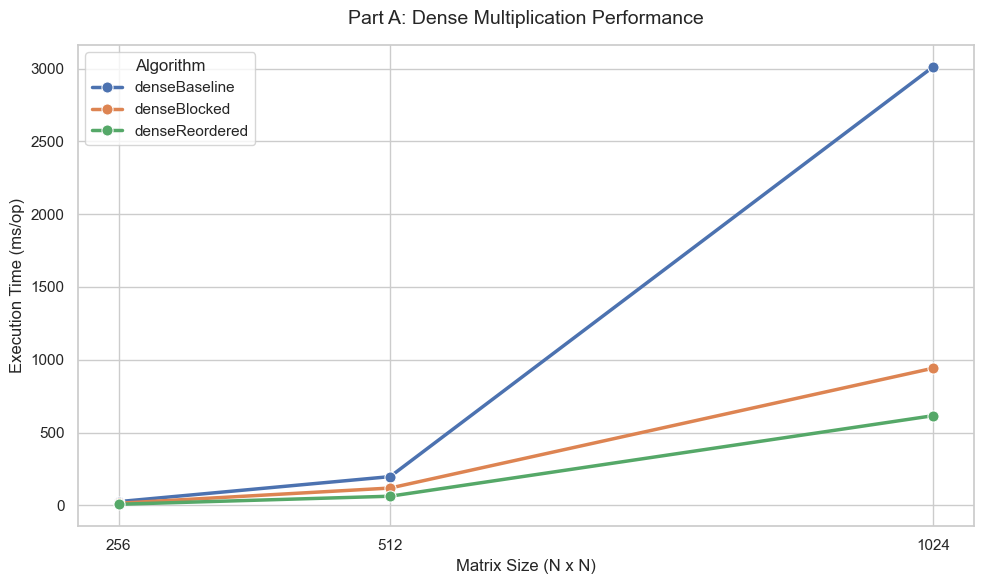

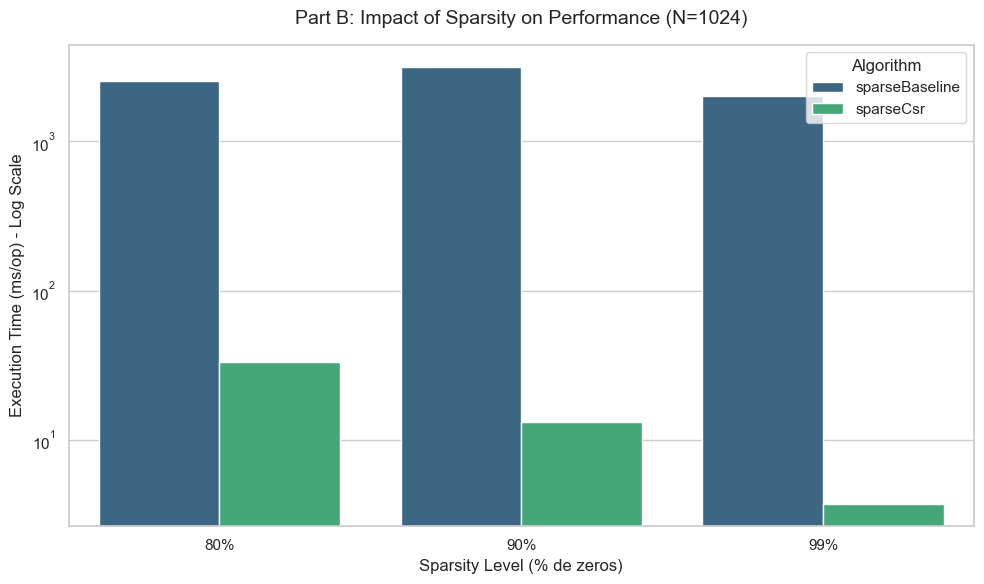

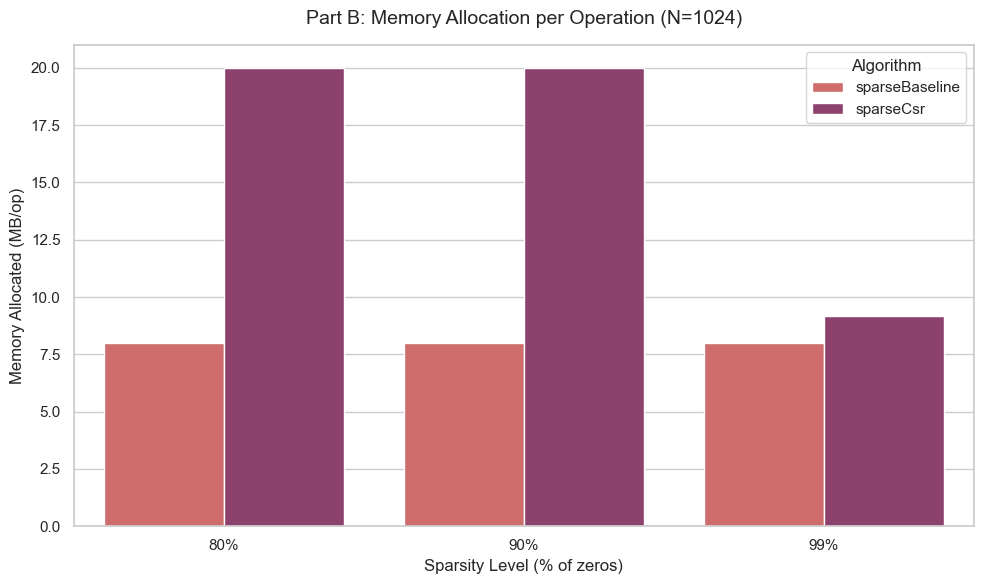

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('benchmark_results.csv')

df = df[df['Unit'] == 'ms/op'].copy()

df['Method'] = df['Benchmark'].apply(lambda x: x.split('.')[-1])

df['Score'] = df['Score'].astype(str).str.replace(',', '.').astype(float)

df_dense = df[df['Param: sparsity'].isna()].copy()
df_sparse = df[df['Param: sparsity'].notna()].copy()


plt.figure()
sns.lineplot(
    data=df_dense,
    x='Param: n',
    y='Score',
    hue='Method',
    marker='o',
    linewidth=2.5,
    markersize=8
)

plt.title('Part A: Dense Multiplication Performance', fontsize=14, pad=15)
plt.xlabel('Matrix Size (N x N)', fontsize=12)
plt.ylabel('Execution Time (ms/op)', fontsize=12)
plt.xticks([256, 512, 1024])
plt.legend(title='Algorithm')
plt.tight_layout()
plt.savefig('dense_performance.png', dpi=300)
plt.show()


df_sparse_1024 = df_sparse[df_sparse['Param: n'] == 1024].copy()

df_sparse_1024['Sparsity %'] = (df_sparse_1024['Param: sparsity'] * 100).astype(int).astype(str) + '%'

plt.figure()
sns.barplot(
    data=df_sparse_1024,
    x='Sparsity %',
    y='Score',
    hue='Method',
    palette='viridis'
)

plt.title('Part B: Impact of Sparsity on Performance (N=1024)', fontsize=14, pad=15)
plt.xlabel('Sparsity Level (% de zeros)', fontsize=12)
plt.ylabel('Execution Time (ms/op) - Log Scale', fontsize=12)
plt.yscale('log')
plt.legend(title='Algorithm')
plt.tight_layout()
plt.savefig('sparse_performance.png', dpi=300)
plt.show()


df = pd.read_csv('benchmark_results.csv')

df_mem = df[df['Unit'] == 'B/op'].copy()

df_mem['Method'] = df_mem['Benchmark'].apply(lambda x: x.split(':')[0].split('.')[-1])

df_mem['Score'] = df_mem['Score'].astype(str).str.replace(',', '.').astype(float)

df_mem['Score_MB'] = df_mem['Score'] / (1024 * 1024)

mem_1024_sparse = df_mem[(df_mem['Param: n'] == 1024) & df_mem['Param: sparsity'].notna()].copy()
mem_1024_sparse['Sparsity %'] = (mem_1024_sparse['Param: sparsity'] * 100).astype(int).astype(str) + '%'

plt.figure()
sns.barplot(
    data=mem_1024_sparse,
    x='Sparsity %',
    y='Score_MB',
    hue='Method',
    palette='flare'
)

plt.title('Part B: Memory Allocation per Operation (N=1024)', fontsize=14, pad=15)
plt.xlabel('Sparsity Level (% of zeros)', fontsize=12)
plt.ylabel('Memory Allocated (MB/op)', fontsize=12)
plt.legend(title='Algorithm')
plt.tight_layout()
plt.savefig('memory_allocation_1024.png', dpi=300)
plt.show()